In [1]:
import os
from pathlib import Path
from kaggle_secrets import UserSecretsClient

# 1. Credentials
user_secrets = UserSecretsClient()
os.environ["HF_TOKEN"] = user_secrets.get_secret("HF_TOKEN")
os.environ["WANDB_API_KEY"] = user_secrets.get_secret("WANDB_API_KEY")

# 2. Repo Setup
REPO_DIR = Path("/kaggle/working/trainbench")
if not REPO_DIR.exists():
  !git clone https://github.com/akash5100/trainbench.git {REPO_DIR}
  %cd {REPO_DIR}
  !make setup-gpu
else:
  %cd {REPO_DIR}
  !git pull

# 3. Symlink / Copy of Precomputed Cache if exists
SRC = "/kaggle/input/notebooks/akzsh5100/sigmoid-distill"

!rm -rf /kaggle/working/.cache /kaggle/working/trainbench/.cache
!ln -sfn {SRC}/.cache /kaggle/working/.cache
!ln -sfn {SRC}/.cache /kaggle/working/trainbench/.cache

!rm -rf /kaggle/working/checkpoints /kaggle/working/trainbench/checkpoints
!mkdir -p /kaggle/working/checkpoints /kaggle/working/trainbench/checkpoints

!cp -vn {SRC}/checkpoints/*.pt /kaggle/working/checkpoints/ 2>/dev/null || true
!cp -vn {SRC}/checkpoints/*.pt /kaggle/working/trainbench/checkpoints/ 2>/dev/null || true

print("Ready! Checkpoints directory is writable.")

print(">>> Cache is linked and ready:")
!ls -lh /kaggle/working/.cache

/kaggle/working/trainbench
Already up to date.
'/kaggle/input/notebooks/akzsh5100/sigmoid-distill/checkpoints/student_baseline_a0.0_best.pt' -> '/kaggle/working/checkpoints/student_baseline_a0.0_best.pt'
'/kaggle/input/notebooks/akzsh5100/sigmoid-distill/checkpoints/student_T1.0_a0.5_best.pt' -> '/kaggle/working/checkpoints/student_T1.0_a0.5_best.pt'
'/kaggle/input/notebooks/akzsh5100/sigmoid-distill/checkpoints/student_T4.0_a0.5_best.pt' -> '/kaggle/working/checkpoints/student_T4.0_a0.5_best.pt'
'/kaggle/input/notebooks/akzsh5100/sigmoid-distill/checkpoints/teacher_head_best.pt' -> '/kaggle/working/checkpoints/teacher_head_best.pt'
'/kaggle/input/notebooks/akzsh5100/sigmoid-distill/checkpoints/student_baseline_a0.0_best.pt' -> '/kaggle/working/trainbench/checkpoints/student_baseline_a0.0_best.pt'
'/kaggle/input/notebooks/akzsh5100/sigmoid-distill/checkpoints/student_T1.0_a0.5_best.pt' -> '/kaggle/working/trainbench/checkpoints/student_T1.0_a0.5_best.pt'
'/kaggle/input/notebooks/akzsh5

In [2]:
!pip uninstall -y torchaudio

Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130


In [3]:
# Base arguments shared across all runs
base_args = (
    "--data-root /kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017 "
    "--cache-dir /kaggle/working/.cache "
    "--save-dir /kaggle/working/checkpoints "
    "--teacher-model google/siglip2-so400m-patch14-384 "
    "--student-model google/siglip2-base-patch16-256 "
    "--teacher-epochs 10 "
    "--student-epochs 10 "
    "--batch-size 64 "
    "--num-workers 2 "
    "--lr 1e-3 "
    "--mixed-precision "
    "--wandb "
    "--project siglip2-distill-coco"
)

# # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# # ABLATION 1: alpha = 0.9 (Distillation dominates, only 10% hard GT)
# # ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# print(">>> RUN 1/4: T=1.0 at alpha=0.9")
# !torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
#   --kd-alpha 0.9 --kd-temperature 1.0

# print(">>> RUN 2/4: T=4.0 at alpha=0.9")
# !torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
#   --kd-alpha 0.9 --kd-temperature 4.0


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ABLATION 2: alpha = 1.0 (Pure Distillation, 0% hard GT)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
!torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
  --kd-alpha 1.0 --kd-temperature 0.5

!torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
  --kd-alpha 1.0 --kd-temperature 1.0

!torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
  --kd-alpha 1.0 --kd-temperature 1.5

!torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
  --kd-alpha 1.0 --kd-temperature 2.0

!torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
  --kd-alpha 1.0 --kd-temperature 3.0

!torchrun --nproc_per_node=2 -m experiments.sigmoid_distill.train {base_args} \
  --kd-alpha 1.0 --kd-temperature 6.0

W1125 05:59:52.201000 147 torch/distributed/run.py:851] 
W1125 05:59:52.201000 147 torch/distributed/run.py:851] *****************************************
W1125 05:59:52.201000 147 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1125 05:59:52.201000 147 torch/distributed/run.py:851] *****************************************
TF32 disabled for Compute Capability 7.5 (Pre-Ampere GPU, e.g. Tesla T4).
Configuring AMP with dtype=torch.float16.
Found cached teacher logits at /kaggle/working/.cache/teacher_logits_train.npz. Skipping Phase 1.
config.json: 100%|██████████████████████████████| 276/276 [00:00<00:00, 816kB/s]
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Mode

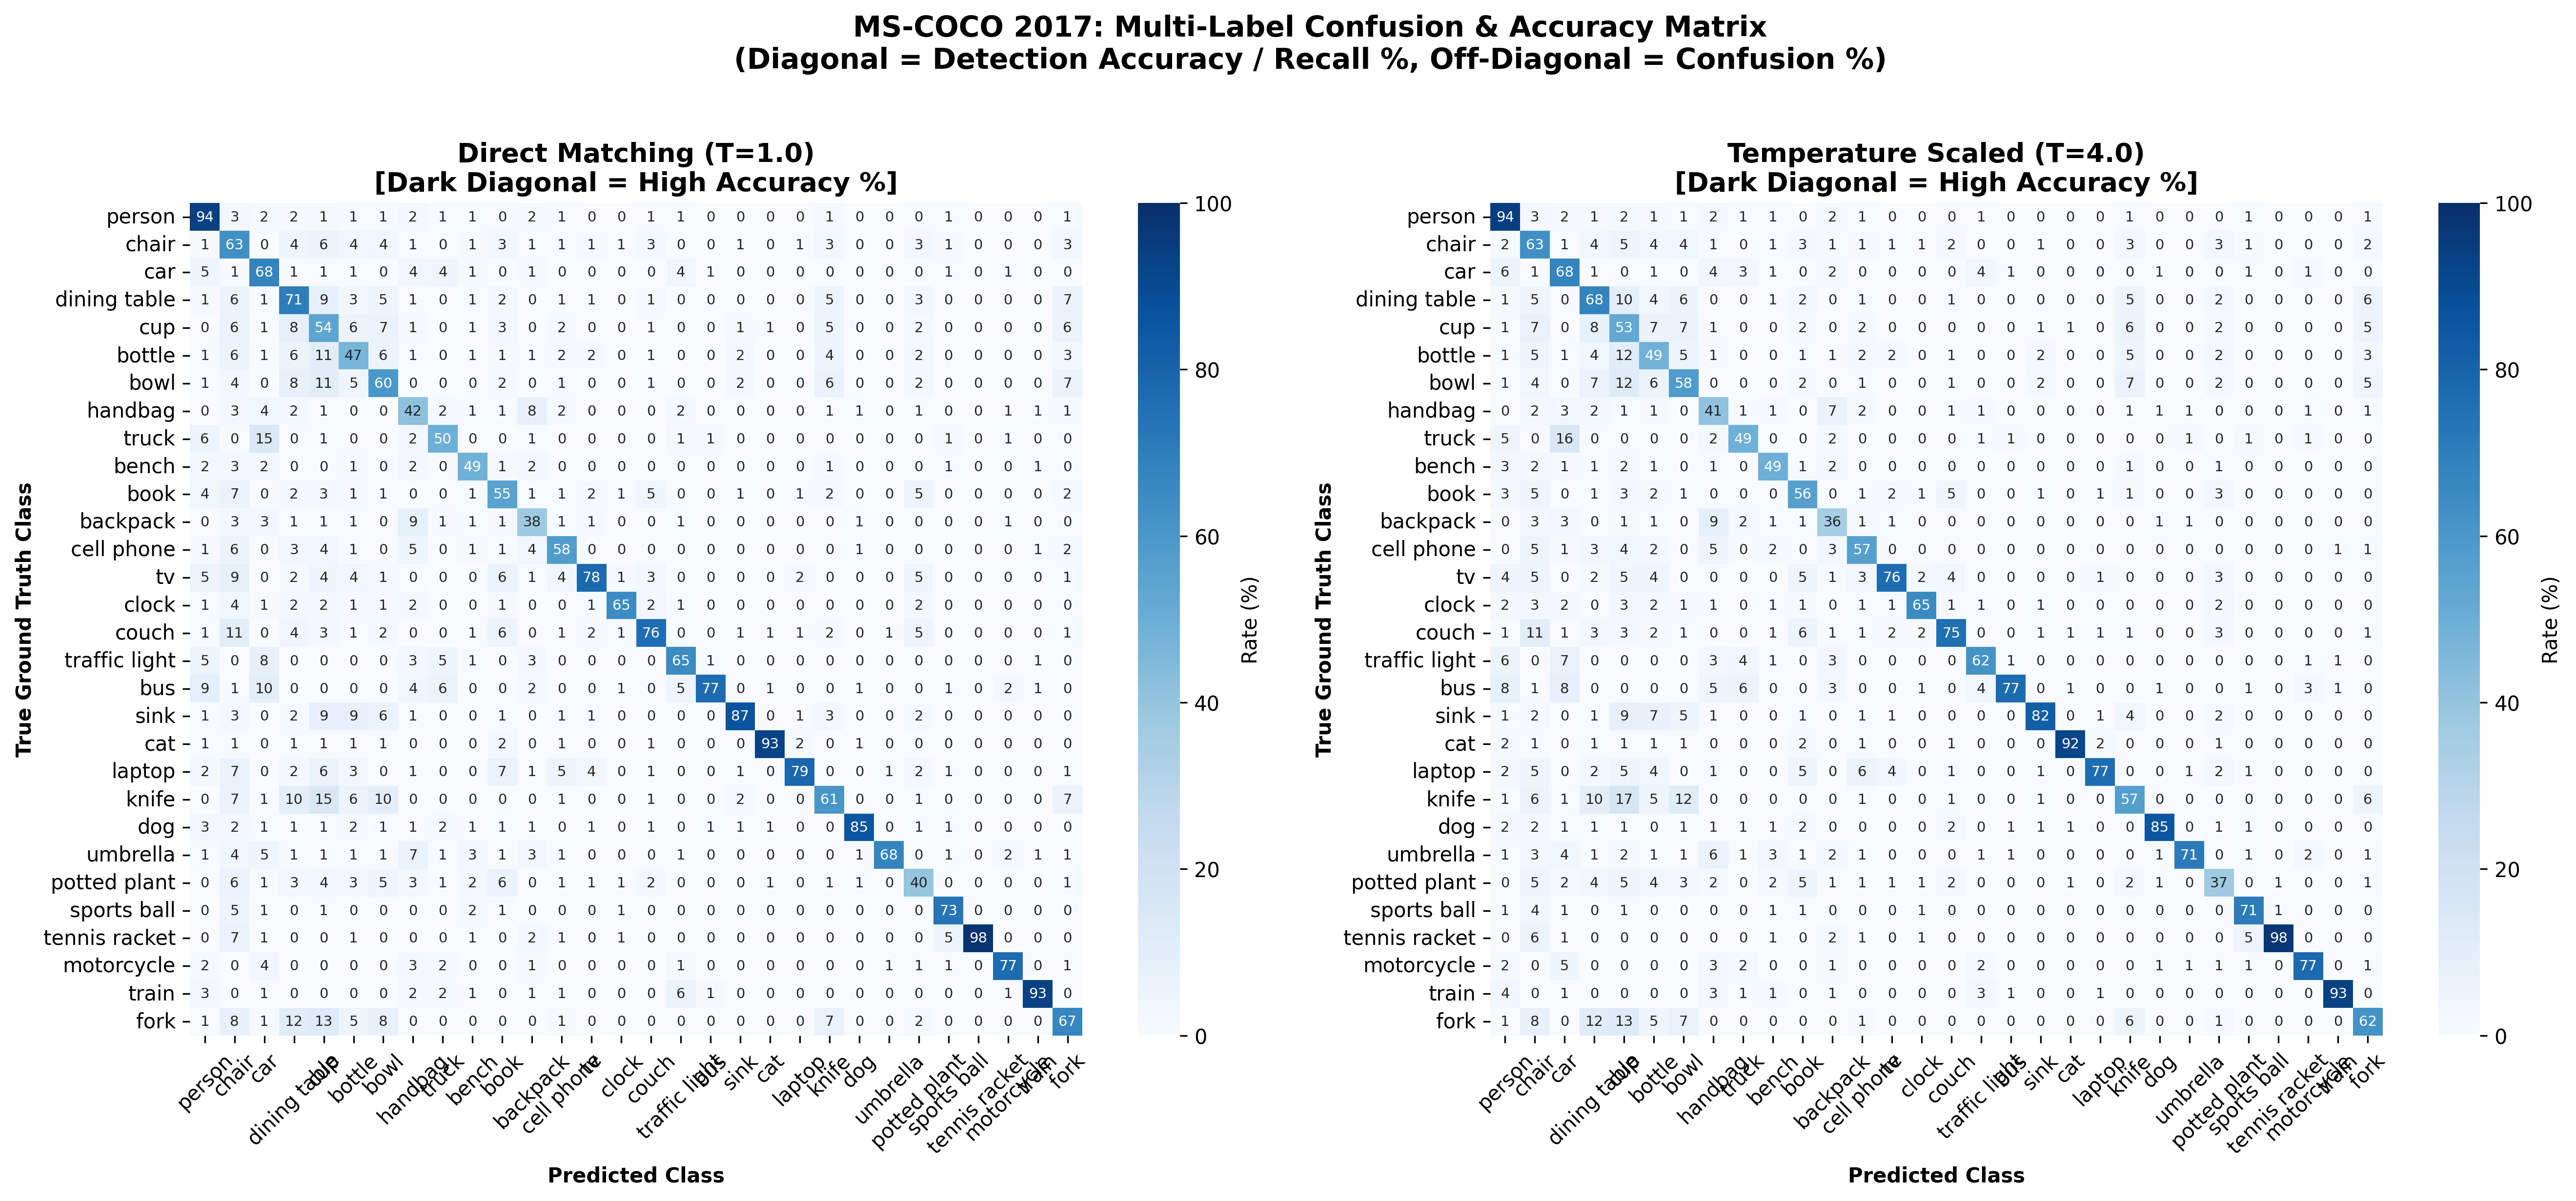

Saved normal confusion matrix to /kaggle/working/accuracy_confusion_matrix.png


In [8]:
# Function with True Accuracy (Recall %) on the diagonal
def compute_accuracy_matrix(ckpt_path):
  head = MultiLabelHead(embed_dim=768, num_classes=80, dropout=0.0)
  state_dict = torch.load(ckpt_path, map_location="cpu")
  state_dict = {
      k.replace("_orig_mod.", "").replace("module.", ""): v
      for k, v in state_dict.items()
  }
  head.load_state_dict(state_dict)
  head.eval()

  with torch.no_grad():
    logits = head(embeds)
    probs = torch.sigmoid(logits)
    preds = (probs >= 0.5).float()

  Y = targets
  row_sums = class_counts[top20_indices, None]

  # 1. Off-diagonal: Hallucination rate (absent class j predicted when true class i present)
  fp_mask = preds * (1.0 - Y)
  C = (Y.T @ fp_mask).numpy()
  C_sub = C[np.ix_(top20_indices, top20_indices)]
  C_norm = (C_sub / np.maximum(1, row_sums)) * 100.0

  # 2. DIAGONAL: Real Accuracy / Recall % (class i present AND correctly predicted)
  tp = ((preds == 1.0) & (Y == 1.0)).sum(dim=0).numpy()
  tp_sub = tp[top20_indices]
  recall_diag = (tp_sub / np.maximum(1, class_counts[top20_indices])) * 100.0

  # Fill diagonal with true detection accuracy
  for idx, rec in enumerate(recall_diag):
    C_norm[idx, idx] = rec

  return C_norm


# Compute for both
Acc_t1 = compute_accuracy_matrix(
    "/kaggle/working/checkpoints/student_T1.0_a0.5_best.pt"
)
Acc_t4 = compute_accuracy_matrix(
    "/kaggle/working/checkpoints/student_T4.0_a0.5_best.pt"
)

# Plot classic confusion matrix with DARK DIAGONAL
fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=300)

sns.heatmap(
    Acc_t1,
    ax=axes[0],
    xticklabels=top20_names,
    yticklabels=top20_names,
    cmap="Blues",
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    annot_kws={"size": 7},
    cbar_kws={"label": "Rate (%)"},
)
axes[0].set_title(
    "Direct Matching (T=1.0)\n[Dark Diagonal = High Accuracy %]",
    fontsize=13,
    fontweight="bold",
)
axes[0].set_xlabel("Predicted Class", fontweight="semibold")
axes[0].set_ylabel("True Ground Truth Class", fontweight="semibold")

sns.heatmap(
    Acc_t4,
    ax=axes[1],
    xticklabels=top20_names,
    yticklabels=top20_names,
    cmap="Blues",
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    annot_kws={"size": 7},
    cbar_kws={"label": "Rate (%)"},
)
axes[1].set_title(
    "Temperature Scaled (T=4.0)\n[Dark Diagonal = High Accuracy %]",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Predicted Class", fontweight="semibold")
axes[1].set_ylabel("True Ground Truth Class", fontweight="semibold")

for ax in axes:
  ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "MS-COCO 2017: Multi-Label Confusion & Accuracy Matrix\n(Diagonal ="
    " Detection Accuracy / Recall %, Off-Diagonal = Confusion %)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("/kaggle/working/accuracy_confusion_matrix.png", dpi=300)
plt.show()
print(
    "Saved normal confusion matrix to"
    " /kaggle/working/accuracy_confusion_matrix.png"
)

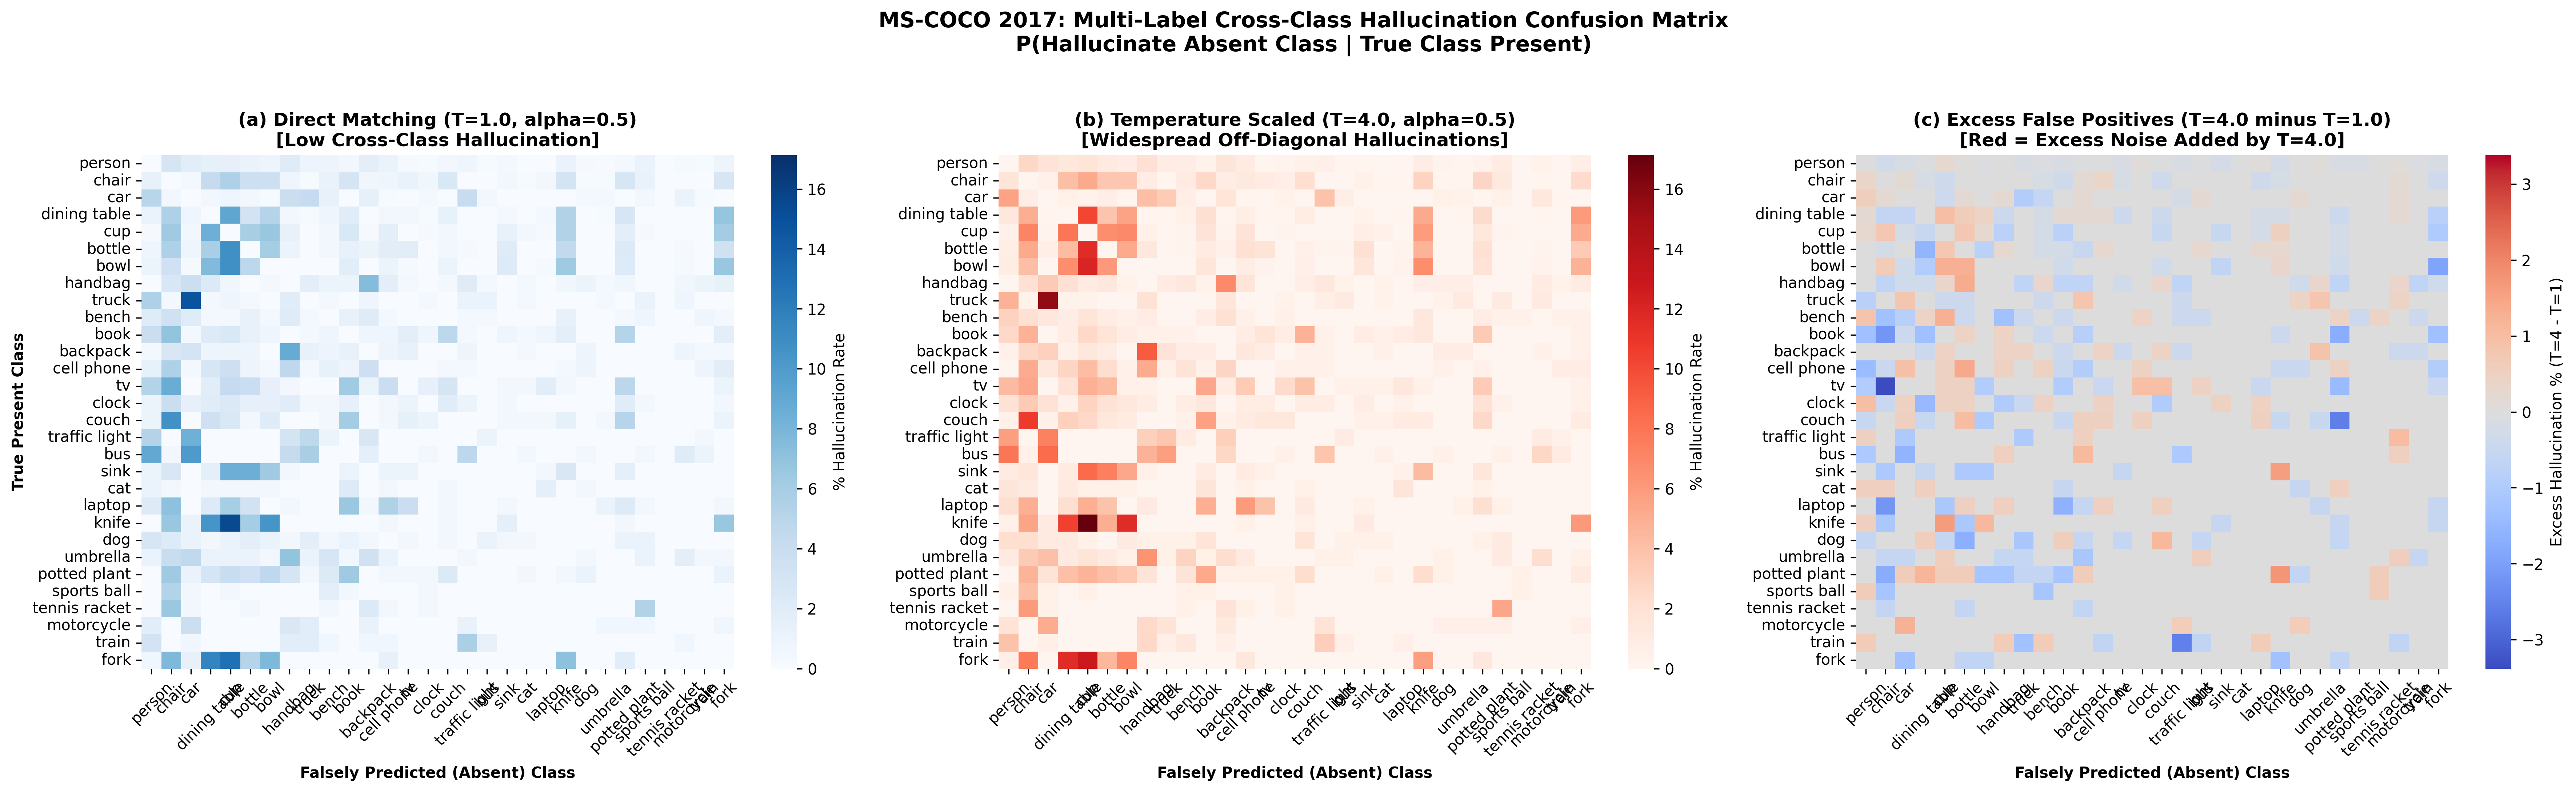

Saved confusion matrix to /kaggle/working/confusion_matrix.png


In [7]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Import the exact model head architecture
from trainbench.models.torch.lit_classifier import MultiLabelHead

# 1. Load cached validation embeddings and targets
val_data = np.load("/kaggle/working/.cache/student_embeds_val.npz")
embeds = torch.from_numpy(val_data["embeddings"]).float()  # (5000, 768)
targets = torch.from_numpy(val_data["targets"]).float()    # (5000, 80)

# COCO 80 Category Names
COCO_CLASSES = [
    'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat',
    'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat',
    'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack',
    'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
    'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
    'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop',
    'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
    'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

# Pick Top 20 most frequent classes for a clean heatmap
class_counts = targets.sum(dim=0).numpy()
top20_indices = np.argsort(class_counts)[::-1][:30]
top20_names = [COCO_CLASSES[i] for i in top20_indices]

# 2. Forward pass through MultiLabelHead
def compute_hallucination_matrix(ckpt_path):
    head = MultiLabelHead(embed_dim=768, num_classes=80, dropout=0.0)
    state_dict = torch.load(ckpt_path, map_location="cpu")
    # Clean any DDP/compile prefix if present
    state_dict = {k.replace("_orig_mod.", "").replace("module.", ""): v for k, v in state_dict.items()}
    head.load_state_dict(state_dict)
    head.eval()
    
    with torch.no_grad():
        logits = head(embeds)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()
    
    # C[i, j] = True class i present AND class j absent BUT predicted
    # Vectorized: Y.T @ (Preds * (1 - Y))
    Y = targets
    fp_mask = preds * (1.0 - Y)
    C = (Y.T @ fp_mask).numpy()
    
    # Slice Top 20 classes
    C_sub = C[np.ix_(top20_indices, top20_indices)]
    
    # Normalize by frequency of row class (P(hallucinate j | i present) in %)
    row_sums = class_counts[top20_indices, None]
    C_norm = (C_sub / np.maximum(1, row_sums)) * 100.0
    np.fill_diagonal(C_norm, 0)
    return C_norm

# 3. Compute for T=1.0 and T=4.0
C_t1 = compute_hallucination_matrix("/kaggle/working/checkpoints/student_T1.0_a0.5_best.pt")
C_t4 = compute_hallucination_matrix("/kaggle/working/checkpoints/student_T4.0_a0.5_best.pt")
Delta = C_t4 - C_t1  # Excess false positives under T=4.0

# 4. Plot 3-Panel Comparison
fig, axes = plt.subplots(1, 3, figsize=(24, 7), dpi=300)

vmax = max(C_t1.max(), C_t4.max())
sns.heatmap(C_t1, ax=axes[0], xticklabels=top20_names, yticklabels=top20_names,
            cmap="Blues", vmin=0, vmax=vmax, cbar_kws={'label': '% Hallucination Rate'})
axes[0].set_title("(a) Direct Matching (T=1.0, alpha=0.5)\n[Low Cross-Class Hallucination]", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Falsely Predicted (Absent) Class", fontweight="semibold")
axes[0].set_ylabel("True Present Class", fontweight="semibold")

sns.heatmap(C_t4, ax=axes[1], xticklabels=top20_names, yticklabels=top20_names,
            cmap="Reds", vmin=0, vmax=vmax, cbar_kws={'label': '% Hallucination Rate'})
axes[1].set_title("(b) Temperature Scaled (T=4.0, alpha=0.5)\n[Widespread Off-Diagonal Hallucinations]", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Falsely Predicted (Absent) Class", fontweight="semibold")

# Difference heatmap (T=4.0 minus T=1.0)
diff_vmax = max(abs(Delta.min()), abs(Delta.max()))
sns.heatmap(Delta, ax=axes[2], xticklabels=top20_names, yticklabels=top20_names,
            cmap="coolwarm", center=0, vmin=-diff_vmax, vmax=diff_vmax, cbar_kws={'label': 'Excess Hallucination % (T=4 - T=1)'})
axes[2].set_title("(c) Excess False Positives (T=4.0 minus T=1.0)\n[Red = Excess Noise Added by T=4.0]", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Falsely Predicted (Absent) Class", fontweight="semibold")

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle("MS-COCO 2017: Multi-Label Cross-Class Hallucination Confusion Matrix\nP(Hallucinate Absent Class | True Class Present)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved confusion matrix to /kaggle/working/confusion_matrix.png")

In [6]:
# Print the Top 10 worst confused pairs in plain English
pairs = []
for i in range(len(top20_indices)):
  for j in range(len(top20_indices)):
    if i != j:
      pairs.append(
          (top20_names[i], top20_names[j], C_t1[i, j], C_t4[i, j], Delta[i, j])
      )

# Sort by highest hallucination rate under T=4.0
pairs.sort(key=lambda x: x[3], reverse=True)

print(
    f"{'True Object':<15} | {'Falsely Hallucinated':<20} | {'T=1.0 Rate':<12} |"
    f" {'T=4.0 Rate':<12} | {'Excess under T=4.0'}"
)
print("-" * 80)
for true_cls, false_cls, r1, r4, diff in pairs[:10]:
  print(
      f"{true_cls:<15} | {false_cls:<20} | {r1:6.2f}%      | {r4:6.2f}%     "
      f" | +{diff:.2f}% (T=4 worse)"
  )

True Object     | Falsely Hallucinated | T=1.0 Rate   | T=4.0 Rate   | Excess under T=4.0
--------------------------------------------------------------------------------
truck           | car                  |  14.80%      |  15.60%      | +0.80% (T=4 worse)
bowl            | cup                  |  10.83%      |  12.10%      | +1.27% (T=4 worse)
bottle          | cup                  |  10.82%      |  11.61%      | +0.79% (T=4 worse)
couch           | chair                |  10.77%      |  10.77%      | +0.00% (T=4 worse)
dining table    | cup                  |   9.18%      |  10.18%      | +1.00% (T=4 worse)
backpack        | handbag              |   8.77%      |   9.21%      | +0.44% (T=4 worse)
sink            | cup                  |   8.56%      |   8.56%      | +0.00% (T=4 worse)
bus             | car                  |  10.05%      |   8.47%      | +-1.59% (T=4 worse)
cup             | dining table         |   8.46%      |   7.95%      | +-0.51% (T=4 worse)
bus             |